In [1]:
# ==========================================
# 1. SZEGMENT: Könyvtárak és hardver beállítása
# ==========================================

import torch
from diffusers import DiffusionPipeline
from transformers import BlipProcessor, BlipForConditionalGeneration
import matplotlib.pyplot as plt

Kezdo_szoveg = "krusty crab"
Korok = 5

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
size = 512 if device == "cuda" else 256

CLIP_MIN = 0.15
CLIP_MAX = 0.35

# ==========================================
# 2. SZEGMENT: Modellek egyszeri betöltése
# ==========================================
pipe = DiffusionPipeline.from_pretrained(
    "stabilityai/sd-turbo",
    torch_dtype=dtype,
    variant="fp16" if device == "cuda" else None
).to(device)

processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
model = BlipForConditionalGeneration.from_pretrained(
    "Salesforce/blip-image-captioning-base",
    torch_dtype=dtype
).to(device)

#CLIP (Pontozás)
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

# ==========================================
# 3. SZEGMENT: 1. kör (Szöveg -> Kép -> Szöveg)
# ==========================================


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

... (9 outputs left out)

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

NameError: name 'CLIPModel' is not defined

  0%|          | 0/1 [00:00<?, ?it/s]

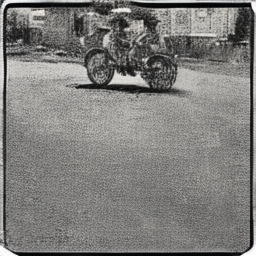

1. képleírás: a black and white photo of a motorcycle


  0%|          | 0/1 [00:00<?, ?it/s]

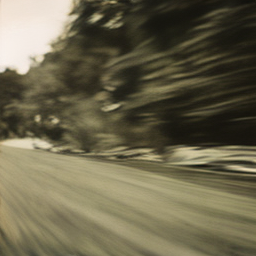

2. képleírás: a blur of trees


In [2]:
prompt_1 = "motorbike"
image_1 = pipe(prompt_1, num_inference_steps=1, guidance_scale=0.0, height=size, width=size).images[0]
display(image_1)

inputs_1 = processor(image_1, return_tensors="pt").to(device, dtype)
with torch.no_grad():
    out_1 = model.generate(**inputs_1, max_new_tokens=20)
caption_1 = processor.decode(out_1[0], skip_special_tokens=True)
print("1. képleírás:", caption_1)


# ==========================================
# 4. SZEGMENT: 2. kör (Új szöveg -> Kép -> Szöveg)
# ==========================================
image_2 = pipe(caption_1, num_inference_steps=1, guidance_scale=0.0, height=size, width=size).images[0]
display(image_2)

inputs_2 = processor(image_2, return_tensors="pt").to(device, dtype)
with torch.no_grad():
    out_2 = model.generate(**inputs_2, max_new_tokens=20)
caption_2 = processor.decode(out_2[0], skip_special_tokens=True)
print("2. képleírás:", caption_2)
